In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Q1: Tuftian plot

- Pick the worst plot you ever published in paper or put in your MSc thesis (you know what I'm talking about, the one that looks real crap!)
- Go through Tufte's principles and annotate all you've done wrong.
- Redo the plot, but this time go for "graphical excellence". 
- Compare the result with what you had before.

## Q2: Planetary positions

The distances of the planets from the Sun (technically, their semi-major axes) are:

In [2]:
a = np.array([0.39, 0.72, 1.00, 1.52, 5.20, 9.54, 19.22, 30.06, 39.48])

These are in units where the Earth-Sun distance is 1 (astronomical units).

The corresponding periods of their orbits (how long they take to go once around the Sun) are, in years

In [3]:
P = np.array([0.24, 0.62, 1.00, 1.88, 11.86, 29.46, 84.01, 164.8, 248.09])

Finally, the names of the planets corresponding to these are:

In [4]:
names = ["Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", 
         "Uranus", "Neptune", "Pluto"]

(technically, pluto isn't a planet anymore, but we still love it :)

  * Plot as points, the periods vs. distances for each planet on a log-log plot.

  * Write the name of the planet next to the point for that planet on the plot

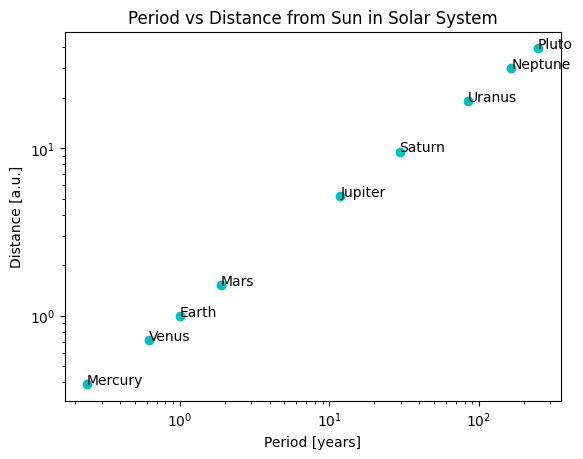

In [18]:
plt.figure()
plt.scatter(P, a, color='c')

for i in range(len(a)):
    plt.text(P[i], a[i], names[i])

plt.xscale("log")
plt.yscale("log")
plt.title("Period vs Distance from Sun in Solar System")
plt.xlabel("Period [years]")
plt.ylabel("Distance [a.u.]")
plt.show()

## Q3: A perfect circle

For an angle $\theta$ in the range $\theta \in [0, 2\pi]$, the polar equations of a circle of radius $R$ are:

$$x = R\cos(\theta)$$

$$y = R\sin(\theta)$$

We want to draw a circle.   

  * Create an array to hold the theta values&mdash;the more we use, the smoother the circle will be
  * Create `x` and `y` arrays from `theta` for your choice of $R$
  * Plot `y` vs. `x`
  
Now, look up the matplotlib `fill()` function, and draw a circle filled in with a solid color.

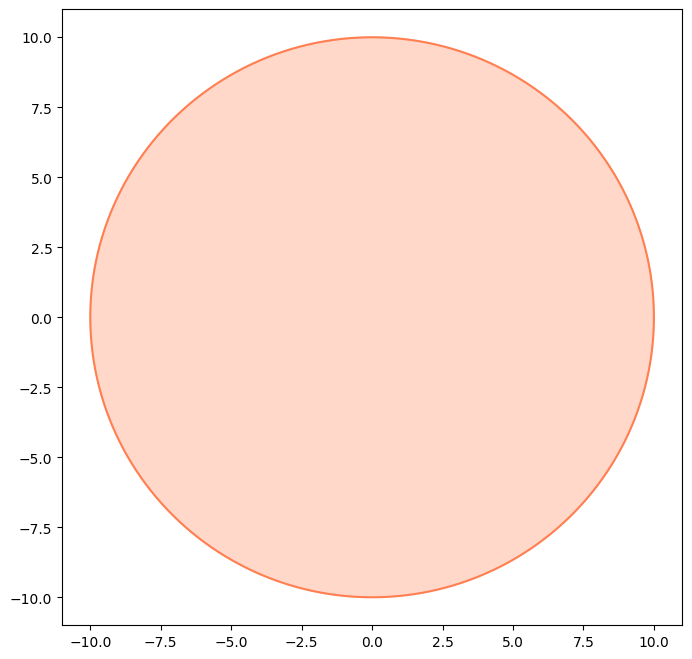

In [29]:
theta = np.arange(0, 2*np.pi, 0.01)
R = 10

x = R * np.cos(theta)
y = R * np.sin(theta)

plt.figure(figsize=(8,8))
plt.plot(x, y, c='coral')
plt.fill(x, y, c='coral', alpha=0.3)
plt.show()

Generalize your circle drawing commands to produce a function, 
```
draw_circle(x0, y0, R, color)
```
that draws the circle.  Here, `(x0, y0)` is the center of the circle, `R` is the radius, and `color` is the color of the circle.  

Now randomly draw 10 circles at different locations, with random radii, and random colors on the same plot.

/tmp/ipykernel_11698/2099913434.py:9: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(x0, y0, c=color)


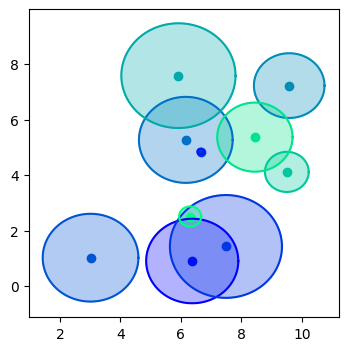

In [53]:
import matplotlib.cm as cm
import matplotlib.colors as colors

def draw_circle(x0, y0, R, color):
    """(x0, y0) is the center of the circle, R is the radius, color is the color"""
    theta = np.arange(0, 2*np.pi, 0.01)
    x = x0 + R * np.cos(theta)
    y = y0 + R * np.sin(theta)
    plt.scatter(x0, y0, c=color)
    plt.plot(x, y, c=color)
    plt.fill(x, y, c=color, alpha=0.3)


x0 = np.random.rand(10)*10
y0 = np.random.rand(10)*10
R = np.random.rand(10)*2
cmap = cm.winter
norm = colors.Normalize(vmin=0, vmax=len(R) - 1)

plt.figure(figsize=(4,4))
for i, (x0, y0, R) in enumerate(zip(x0, y0, R)):
    draw_circle(x0, y0, R, color=cmap(norm(i)))
plt.show()

## Q4: Climate

Download the data file of global surface air temperature averages from here:
https://raw.githubusercontent.com/sbu-python-summer/python-tutorial/master/day-4/nasa-giss.txt
This data comes from: https://data.giss.nasa.gov/gistemp/graphs/

(Don't ask, of course you can download data straight from python! Packages `requests` and `urllib` can both do the job)

There are 3 columns here: the year, the temperature change, and a smoothed representation of the temperature change.  

  * Read in this data using `np.loadtxt()`.  
  * Plot as a line the smoothed representation of the temperature changes.  
  * Plot as points the temperature change (no smoothing).  Color the points blue if they are < 0 and color them red if they are >= 0
  
You might find the numpy `where()` function useful.

In [39]:
import urllib.request

urllib.request.urlretrieve("https://raw.githubusercontent.com/sbu-python-summer/python-tutorial/master/day-4/nasa-giss.txt", "nasa-giss.txt")

('nasa-giss.txt', <http.client.HTTPMessage at 0x7a46a500a200>)

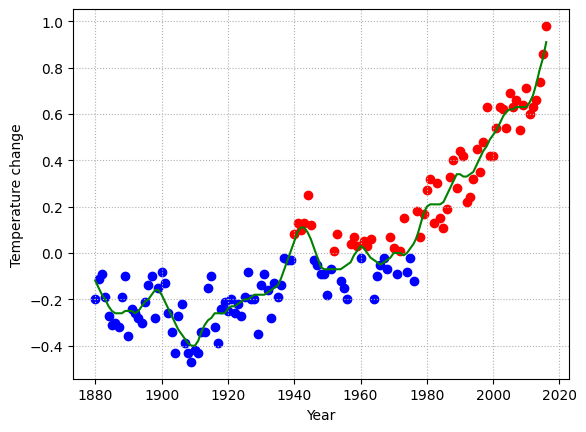

In [74]:
data = np.loadtxt("nasa-giss.txt")

plt.figure()
plt.plot(data[:,0], data[:,2], color='green')
data_cold = data[np.where(data[:,1] < 0)]
plt.scatter(data_cold[:,0], data_cold[:,1], color='b')
data_hot = data[np.where(data[:,1] > 0)]
plt.scatter(data_hot[:,0], data_hot[:,1], color='r')
plt.xlabel("Year")
plt.ylabel("Temperature change")
plt.grid(ls=":")
plt.show()

## Q5: Subplots

matplotlib has a number of ways to create multiple axes in a figure -- look at `plt.subplots()` (http://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.subplot)

Create an `x` array using NumPy with a number of points, spanning from $[0, 2\pi]$.  

Create 3 axes vertically, and do the following:

* Define a new numpy array `f` initialized to a function of your choice.
* Plot f in the top axes
* Compute a numerical derivative of `f`,
   $$ f' = \frac{f_{i+1} - f_i}{\Delta x}$$
  and plot this in the middle axes
* Do this again, this time on $f'$ to compute the second derivative and plot that in the bottom axes


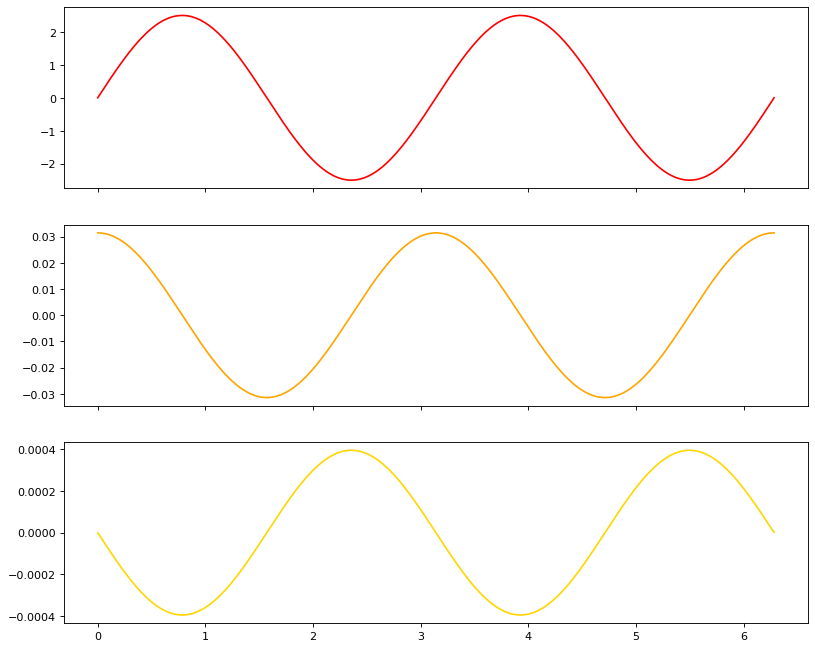

In [93]:
x = np.linspace(0, 2*np.pi, 1000)

f = 5 * np.cos(x) * np.sin(x)
f_first = np.gradient(f)
f_second = np.gradient(f_first)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10), dpi=80, sharex=True)

ax1.plot(x, f, color='r')

ax2.plot(x, f_first, color='orange')

ax3.plot(x, f_second, color='gold')

plt.show()

## Q6: frequent words plotting

In this exercise, we will read the file with the transcription of _Star Trek TOS, Shore Leave_ and calculate the amount of time each word was found. We will then plot the 25 most frequent words and label the plot.

#### Read the file and create the dictionaty {'word':count}

   * Open the `shore_leave.txt` file in the class repository
   * Create the dictionary of the form {'word':count}, where `count` shows the amount of times the word was found in the text. Remember to get rid of the punctuation ("." and ",") and to ensure that all words are lowercase

#### Plot 25 most frequent words

Plot a labelled bar chart of the most frequent 25 words with their frequencies.

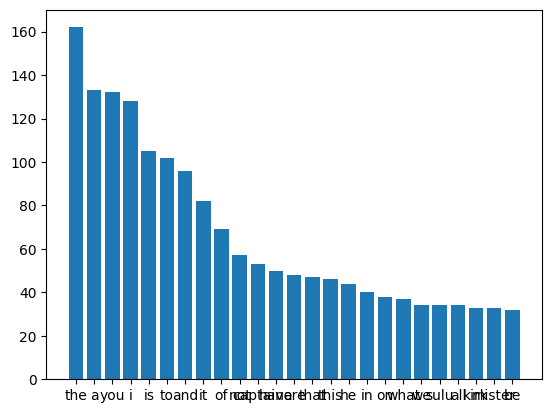

In [122]:
f = open("../lectures/shore_leave.txt", "r")

dictionary = {}

for line in f:
    words = line.split()
    for w in words:
        w = w.lower()
        w = w.replace(".", "").replace(",", "")
        if w not in dictionary:
            dictionary[w] = 1
        else:
            dictionary[w] += 1

dictionary = dict(sorted(dictionary.items(), key = lambda item: item[1], reverse=True))

word = [w for w in dictionary.keys()]
values = [v for v in dictionary.values()]

plt.figure()
plt.bar(word[:25], values[:25])
plt.show()


## Q7: Mandelbrot set

The [Mandelbrot set](https://en.wikipedia.org/wiki/Mandelbrot_set) is defined such that $z_{k+1} = z_k^2 + c$
remains bounded, which is usually taken as $|z_{k+1}| <= 2$
where $c$ is a complex number and we start with $z_0 = 0$

We want to consider a range of $c$, as complex numbers $c = x + iy$,
where $-2 < x < 2$ and $-2 < y < 2$.

For each $c$, identify its position on a Cartesian grid as $(x,y)$ and 
assign a value $N$ that is the number of iterations, $k$, required for $|z_{k+1}|$ to become greater than $2$.

The plot of this function is called the Mandelbrot set.

Here's a simple implementation that just does a fixed number of iterations and then colors points in Z depending on whether they satisfy $|z| \le 2$.  

Your task is to extend this to record the number of iterations it takes for each point in the Z-plane to violate that constraint,
and then plot that data -- it will show more structure


In [ ]:
N = 256
x = np.linspace(-2, 2, N)
y = np.linspace(-2, 2, N)

xv, yv = np.meshgrid(x, y, indexing="ij")

In [ ]:
c = xv + 1j*y

z = np.zeros((N, N), dtype=np.complex128)

for i in range(10):
    z = z**2 + c
    
m = np.ones((N, N))
m[np.abs(z) <= 2] = 0.0

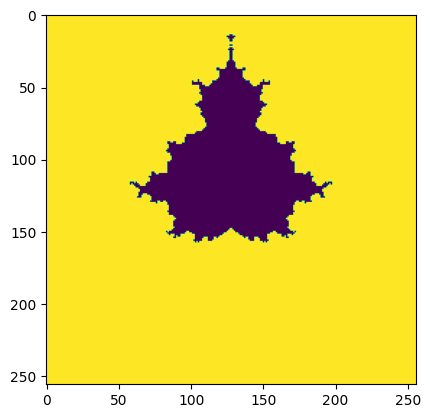

In [ ]:
fig, ax = plt.subplots()
ax.imshow(m)

## Q8: Game of Life visualization

If you've implemented Conway's Game of Life from last lecture, make a visualization of your result using matplotlib

## Q9: Quit smoking

If you ever used ROOT for your scientific plotting, it's not good for your health.
